In [ ]:
import os
import sys
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

TARGET_MOVEMENT = 'Move'

In [28]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [29]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [30]:
cache_path = Configs.all_sensors_dtw_distance_matrix(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"DTW distance matrix for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")   

dtw_matrix = joblib.load(cache_path)

In [31]:
# Load Times for benchmarking
times_path = Configs.ALL_SENSORS_DTW_CALCULATION_TIMES_CACHE
if not os.path.exists(times_path):
    raise FileNotFoundError(f"DTW calculation times not found at {times_path}. Please run the feature extraction notebook first.")

times = joblib.load(times_path)

In [32]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2979.60it/s]

Shape of first series: (72, 9)


Shape of formatted series: (95, 196, 9)


## Local Outlier Factor (LOC)

### Grid Search

In [33]:
# Filtrar o DataFrame bruto para obter os metadados do movimento atual
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

# A sua nova base de cálculo: Repetições ÚNICAS
total_trials_unique = df_filtered.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)

# --- 2. Parâmetros Dinâmicos (Limites de Lixo) ---
# Usamos o total_trials (únicos) para a percentagem, mantendo a coerência com a sua nova métrica
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

print(f"\n--- Preparação LOF (DTW Precomputed) ---")
print(f"Total de repetições únicas analisadas ({TARGET_MOVEMENT}): {total_trials}")
print(f"Taxa mínima confirmada de outliers: {percentagem_conhecida:.2f}%")

# Espaço de Busca da Contamination
min_contam = 0.01
max_contam = known_outlier_rate + 0.10            
contamination_range = np.linspace(min_contam, max_contam, 15)
contamination_range = [round(c, 3) for c in contamination_range] 

# Vizinhos a testar (Valores clássicos, ajustados para matrizes DTW que costumam ser centenas, não milhares)
n_neighbors_options = [3, 5, 7, 10, 15, 20]

results_log = []

for n_neigh in n_neighbors_options:
    for contam in contamination_range:
        
        # TREINO DO LOF (metric='precomputed' porque vamos passar a matriz DTW)
        model = LocalOutlierFactor(n_neighbors=n_neigh, contamination=contam, metric='precomputed')
        
        # O LOF prevê diretamente na matriz de distâncias (dtw_matrix CRUA)
        labels = model.fit_predict(dtw_matrix)
        
        # --- CÁLCULO DE MÉTRICAS (A sua lógica exata!) ---
        results_temp = results_temp_base.copy()
        results_temp['label'] = labels
        
        # Isolar os outliers previstos (-1)
        real_outliers_info = results_temp[results_temp['label'] == -1]
        
        # Garantir que os outliers identificados são únicos por sub e repID
        identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
        
        # Cruzamento (Match)
        matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')
        
        # Encontrar os que falharam (Missing / False Negatives)
        missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
        missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']
        
        # Variáveis da Matriz de Confusão
        TP = len(matched_outliers)
        FP = len(identified_unique) - TP
        FN = len(missing_outliers)
        # TN = total_trials - (TP + FP + FN) # Apenas ilustrativo, não entra no F1
        
        # Prevenir divisão por zero
        if (TP + FP) > 0:
            precision = (TP / (TP + FP)) * 100
            recall = (TP / total_known_outliers) * 100
            f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
            f2_score = (5 * precision * recall) / (4 * precision + recall) if (precision + recall) > 0 else 0
        else:
            precision, recall, f1_score, f2_score = 0.0, 0.0, 0.0, 0.0
            
        # O Lixo Rejeitado agora é baseado no total de repetições ÚNICAS deitadas fora
        percentagem_lixo = (len(identified_unique) / total_trials) * 100
            
        results_log.append({
            'n_neighbors': n_neigh,
            'contamination': contam,
            'Recall': recall,
            'Precision': precision,
            'F1-Score': f1_score,
            'F2-Score': f2_score,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'Percentagem Lixo': percentagem_lixo,
            'identified_unique_df': identified_unique # Guardar para o print final
        })


--- Preparação LOF (DTW Precomputed) ---
Total de repetições únicas analisadas (Move): 95
Taxa mínima confirmada de outliers: 14.74%


In [34]:
# --- Seleção do Melhor Modelo ---
results_df = pd.DataFrame(results_log)

# Limitar o lixo: A percentagem conhecida + 5% de tolerância
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    print(f"Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo. A usar todos.")
    acceptable_models = results_df

# Ordenar pelo Recall e F2-Score
best_results = acceptable_models.sort_values(by=['Recall', 'F2-Score'], ascending=False)
best_params = best_results.iloc[0]

# --- 4. PRINT FINAL (A sua Matriz de Confusão) ---
print(f"\n🏆 VENCEDOR DO GRID SEARCH (LOF - DTW Precomputed):")
print(f"N Neighbors: {best_params['n_neighbors']}")
print(f"Contamination: {best_params['contamination']}")

print(f"\nMétricas do Melhor Modelo:")
print(f"Recall: {best_params['Recall']:.2f}%")
print(f"Precision: {best_params['Precision']:.2f}%")
print(f"F1-Score: {best_params['F1-Score']:.2f}%")
print(f"F2-Score: {best_params['F2-Score']:.2f}%")
print(f"Percentagem de Lixo Rejeitado: {best_params['Percentagem Lixo']:.2f}%")
print(f"TP: {best_params['TP']}, FP: {best_params['FP']}, FN: {best_params['FN']}")


🏆 VENCEDOR DO GRID SEARCH (LOF - DTW Precomputed):
N Neighbors: 10
Contamination: 0.18

Métricas do Melhor Modelo:
Recall: 64.29%
Precision: 52.94%
F1-Score: 58.06%
F2-Score: 61.64%
Percentagem de Lixo Rejeitado: 17.89%
TP: 9, FP: 8, FN: 5


### Train Model

In [35]:
best_n_neighbors = int(best_params['n_neighbors'])
best_contamination = best_params['contamination']

start_time = time.perf_counter()

model = LocalOutlierFactor(n_neighbors=best_n_neighbors, contamination=best_contamination, n_jobs=-1, metric='precomputed')
labels = model.fit_predict(dtw_matrix)

end_time = time.perf_counter()
elapsed_time = end_time - start_time
elapsed_time_with_dtw = elapsed_time + times[TARGET_MOVEMENT]

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(labels)
print(f"Outliers detected at indices: {outlier_indices}")
print(f"Total de Repetições: {len(X_movement)}")
print(f"Outlers Detetados: {len(outlier_indices)}")
print(f"Percentagem de lixo: {len(outlier_indices) / len(X_movement) * 100:.2f}%")
print(f"Percentagem de Retenção: {(len(X_movement) - len(outlier_indices)) / len(X_movement) * 100:.2f}%")
print(f"Tempo de Execução do DBSCAN (sem DTW): {elapsed_time:.2f} segundos")
print(f"Tempo Total (DTW + DBSCAN): {elapsed_time_with_dtw:.2f} segundos")

[ 1  1  1  1  1  1 -1  1  1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1
  1  1  1  1  1  1 -1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1 -1  1  1  1  1 -1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1
  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
Outliers detected at indices: [ 6 12 13 14 15 20 21 22 23 30 35 50 55 62 75 78 79]
Total de Repetições: 95
Outlers Detetados: 17
Percentagem de lixo: 17.89%
Percentagem de Retenção: 82.11%
Tempo de Execução do DBSCAN (sem DTW): 0.00 segundos
Tempo Total (DTW + DBSCAN): 2.35 segundos


In [36]:
# 1. Recriar a lista de identidades NA MESMA ORDEM que o X_movement foi gerado
# Nota: É crucial usar o mesmo filtro e ordem que usou no 'normalize_series'
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT]

# Agrupar pelas chaves únicas para obter a lista de movimentos
# sort=False preserva a ordem de aparição (geralmente mais seguro se não ordenou explicitamente antes)
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()

# Criar um DataFrame auxiliar apenas com os Metadados (Índice 0 = 1º Movimento, Índice 1 = 2º Movimento...)
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# 2. Merge dos Indíces do LOF com os Metadados
if len(metadata_df) != len(X_movement):
    print("⚠️ AVISO CRÍTICO: O número de movimentos não bate certo! Verifique a filtragem.")
else:
    # Filtrar o DataFrame de Metadados usando os índices do LOF
    real_outliers_info = metadata_df.iloc[outlier_indices]
    
    print("Quem são os outliers reais?")
    print(real_outliers_info)

Quem são os outliers reais?
    sub  repID  movID movLabel
6    11      2      9     Move
12   18      3      9     Move
13   18      4      9     Move
14   18      5      9     Move
15    2      1      9     Move
20    5      1      9     Move
21    5      2      9     Move
22    5      3      9     Move
23    5      4      9     Move
30   10      1      9     Move
35   16      1      9     Move
50   15      1      9     Move
55    3      1      9     Move
62   14      3      9     Move
75    4      1      9     Move
78    4      4      9     Move
79    4      5      9     Move


In [37]:
# 1. Garantir que os outliers identificados também são únicos por sub e repID
# Assim, se um algoritmo deitar fora 3 'movID' da mesma 'repID', conta apenas como 1 True Positive
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# 2. Cruzamento (Match)
matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

# 3. Encontrar os que falharam (Missing / False Negatives)
missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# --- CÁLCULO DAS MÉTRICAS ---
metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- MATRIZ DE CONFUSÃO (Baseada em sub+repID) ---
True Positives (Identificados e no CSV) : 3
False Positives (Identificados, não CSV): 14
False Negatives (No CSV, não identificados): 11
True Negatives (Normais, mantidos normais): 67
--------------------------------------------------
Missing outliers (Escaparam ao algoritmo):
    sub  repID
0     2      2
3     5      5
4     7      1
5     8      1
6     9      1
7    11      1
8    12      1
9    13      1
11   16      5
12   18      2
13   19      2

Precision (Precisão) (Falsos Alarmes): 3/17 (17.65%)
Recall (Taxa de Acerto): 3/14 (21.43%)
F1-Score: 19.35%
F2-Score: 20.55%


### Plot Things

A desenhar trajetórias do Ombro...


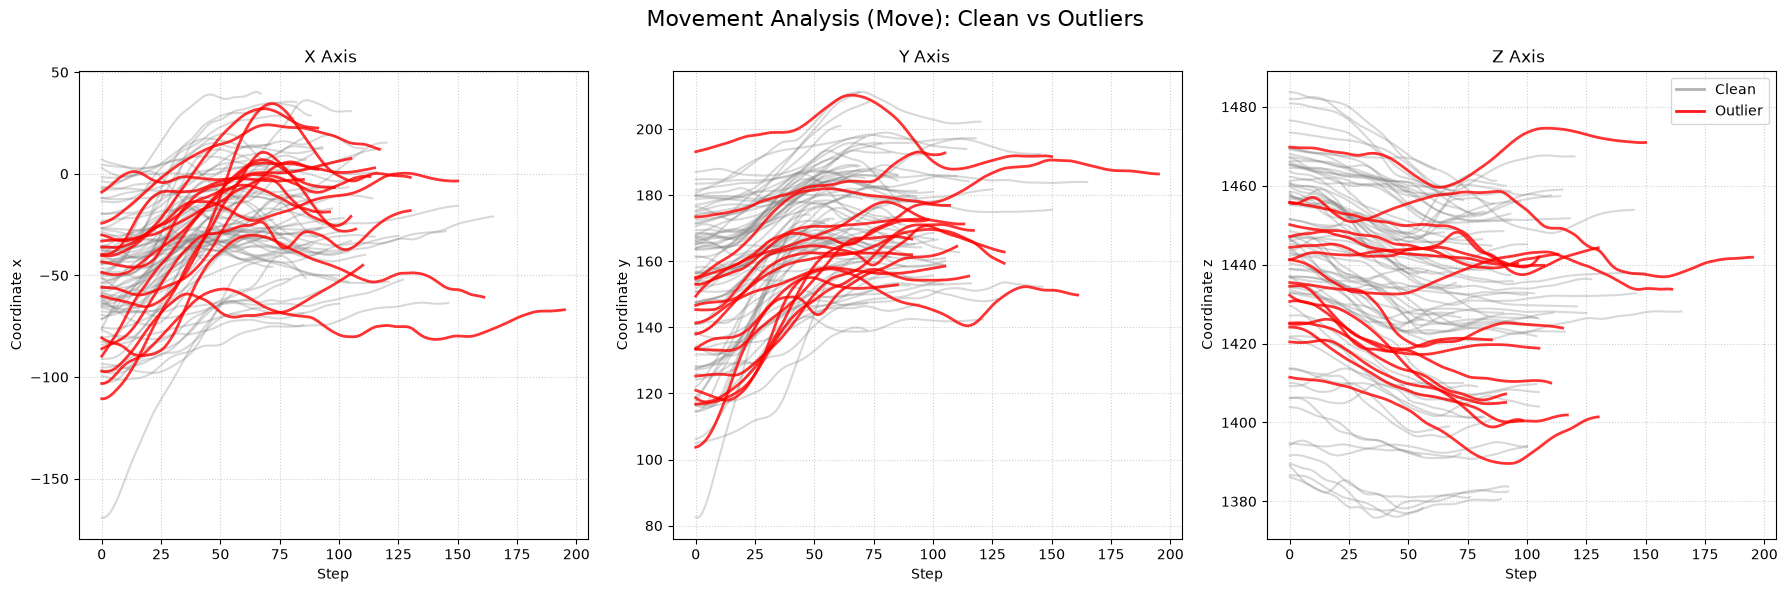

A desenhar trajetórias do Cotovelo...


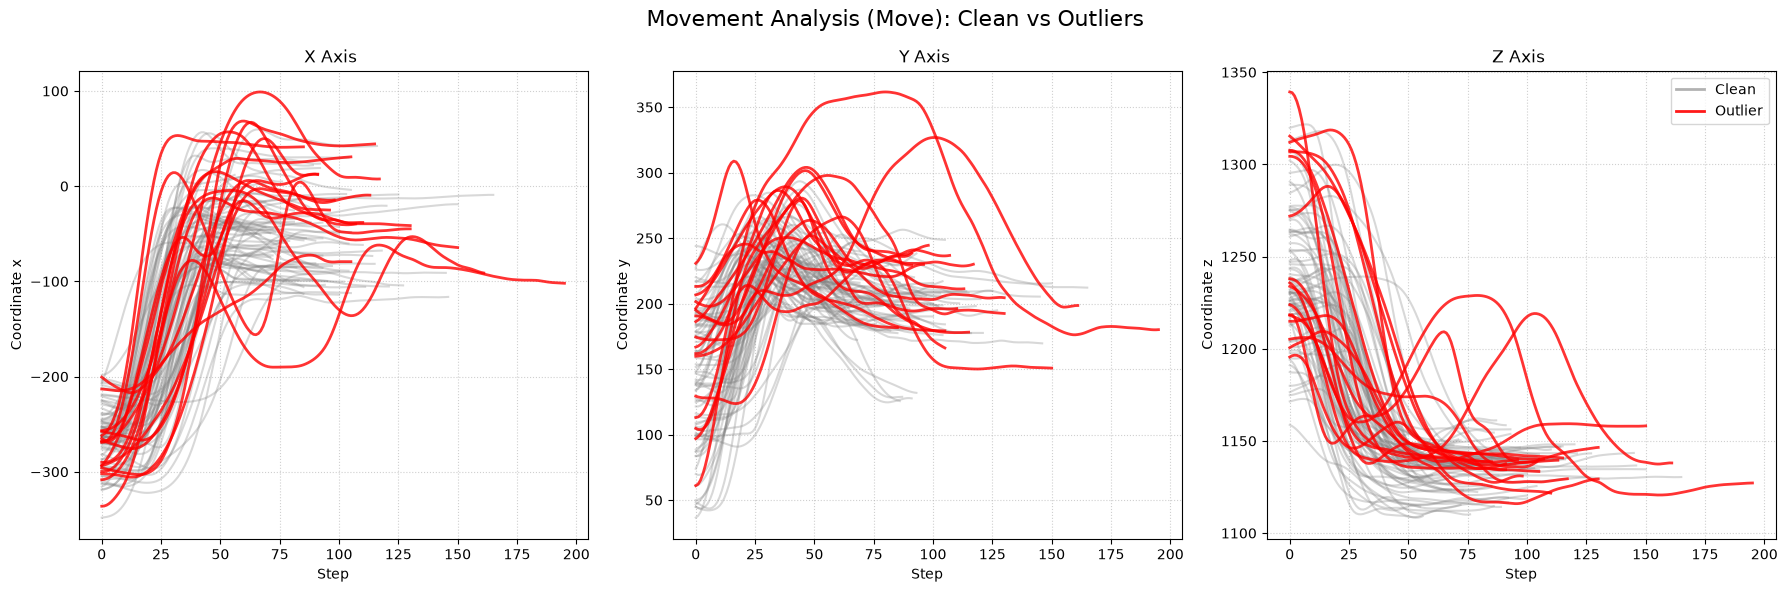

A desenhar trajetórias do Pulso...


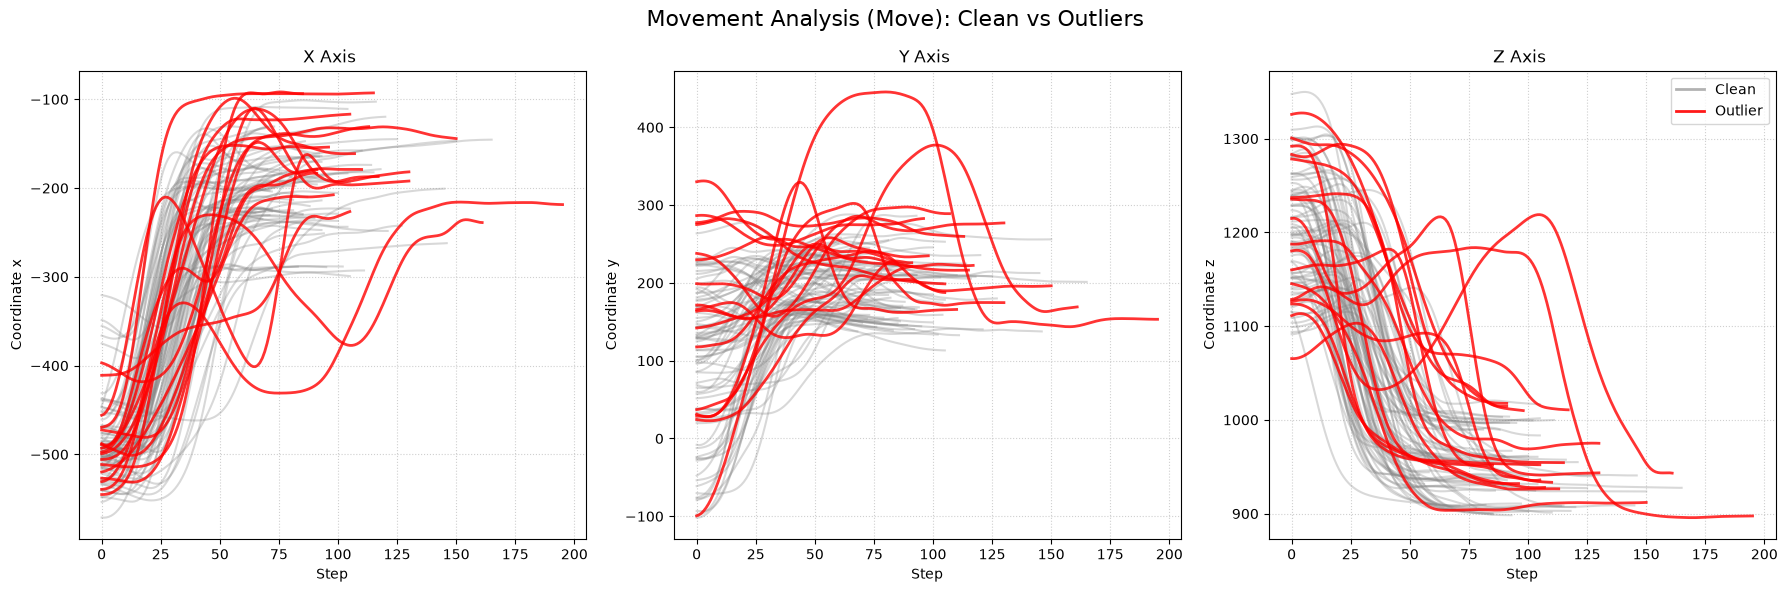

In [38]:
# 1. Ver as trajetórias do Ombro (Índices 0, 1, 2)
print("A desenhar trajetórias do Ombro...")
plot_movement_data(X_movement_clean[:, :, 0:3], X_movement_outliers[:, :, 0:3], TARGET_MOVEMENT)

# 2. Ver as trajetórias do Cotovelo (Índices 3, 4, 5)
print("A desenhar trajetórias do Cotovelo...")
plot_movement_data(X_movement_clean[:, :, 3:6], X_movement_outliers[:, :, 3:6], TARGET_MOVEMENT)

# 3. Ver as trajetórias do Pulso/Mão (Índices 6, 7, 8)
print("A desenhar trajetórias do Pulso...")
plot_movement_data(X_movement_clean[:, :, 6:9], X_movement_outliers[:, :, 6:9], TARGET_MOVEMENT)

In [39]:
# ---------------------------------------------------------
# PASSAR A FACA: Limpar e isolar APENAS o movimento pretendido
# ---------------------------------------------------------

df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()

# Garantir que se tem apenas as chaves identificadoras dos outliers
outliers_keys = real_outliers_info[['sub', 'repID', 'movID', 'movLabel']].copy()

# Fazer um merge (Anti-Join) do dataframe FILTRADO com a lista de outliers
# O indicator=True cria uma coluna chamada '_merge' que nos diz de onde veio a linha
df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID', 'movLabel'], how='left', indicator=True)

# Manter APENAS as linhas que estão limpas ('left_only')
df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])

# --- VERIFICAÇÃO ---
print(f"--- RESUMO DA LIMPEZA ({TARGET_MOVEMENT}) ---")
print(f"Linhas do movimento {TARGET_MOVEMENT} antes da limpeza: {len(df_target_only)}")
print(f"Linhas removidas (pertencentes a outliers): {len(df_target_only) - len(df_cleaned)}")
print(f"Linhas do movimento {TARGET_MOVEMENT} limpas: {len(df_cleaned)}")

# Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
print(f"Movimentos originais eram {total_trials}, removemos {n_outliers}, batem certo? {len(movimentos_restantes) == (total_trials - n_outliers)}")

save_path = Configs.cached_all_sensors_dtw_inliers('LOF', TARGET_MOVEMENT) 
joblib.dump(df_cleaned, save_path)

--- RESUMO DA LIMPEZA (Move) ---
Linhas do movimento Move antes da limpeza: 9095
Linhas removidas (pertencentes a outliers): 1705
Linhas do movimento Move limpas: 7390

Movimentos 'Move' que SOBRARAM: 78
Movimentos originais eram 95, removemos 17, batem certo? True


['/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/ICater/ICater_Shoulder_Elbow_Hand/cache/metadata/all_sensors_dtw/inliers/all_sensors_dtw_inliers_LOF_Move.pkl']